# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Keyla Farrelia
- **Email:** ds156b6x0882@student.devacademy.id
- **ID Dicoding:** DS156B6X0882

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pola perubahan jumlah rata-rata penyewaan sepeda per hari berdasarkan bulan dan musim sepanjang tahun 2011–2012, serta pada bulan apa tercatat rata-rata tertinggi, sebagai dasar penentuan jadwal promosi dan penambahan armada?
- **Pertanyaan 2:** Bagaimana perbandingan pola rata-rata penyewaan sepeda per jam antara hari kerja (*working day*) dan hari bukan kerja (*non-working day*) sepanjang tahun 2011–2012, serta pada jam berapa terjadi puncak pemakaian tertinggi, sebagai dasar pengaturan kapasitas operasional?
- ...

## Import Semua Packages/Library yang Digunakan

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan gaya visualisasi
sns.set(style='whitegrid')

## Data Wrangling

### Gathering Data

#### Load df ...

In [16]:
# Memuat dataset day.csv dan hour.csv
day_df = pd.read_csv("/content/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [17]:
hour_df = pd.read_csv("/content/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset `day.csv` berisi data agregasi penyewaan sepeda harian dengan 16 kolom.
- Dataset `hour.csv` berisi data penyewaan sepeda per jam dengan 17 kolom (terdapat tambahan kolom `hr`).

### Assessing Data

#### Identifying ... problem

In [18]:
# Memeriksa tipe data dan missing value pada day_df
day_df.info()
print("\nJumlah missing values day_df:")
print(day_df.isna().sum())
print("\nJumlah duplikasi day_df:", day_df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Jumlah missing values day_df:
instant       0
dteday        0
season        0
yr            

In [19]:
# Memeriksa tipe data dan missing value pada hour_df
hour_df.info()
print("\nJumlah missing values hour_df:")
print(hour_df.isna().sum())
print("\nJumlah duplikasi hour_df:", hour_df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

Jumlah missing values hour_df:
instant       0
d

In [20]:
# Memeriksa ringkasan statistik dan potensi outlier
display(day_df.describe())
display(hour_df.describe())

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [21]:
# Pengecekan outlier pada variabel numerik utama (cnt) menggunakan metode IQR
def check_outliers_iqr(df, col_name):
    Q1 = df[col_name].quantile(0.25)
    Q3 = df[col_name].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col_name] < lower_bound) | (df[col_name] > upper_bound)]
    print(f"Jumlah outlier pada {col_name}: {len(outliers)} baris")

check_outliers_iqr(day_df, 'cnt')
check_outliers_iqr(hour_df, 'cnt')

Jumlah outlier pada cnt: 0 baris
Jumlah outlier pada cnt: 505 baris


**Steps to Take:**
Berdasarkan temuan pada tahap Assessing Data di atas, berikut adalah langkah-langkah yang akan dilakukan pada tahap Cleaning Data:
1. **Mengubah Tipe Data Tanggal (`datetime`):** Mengonversi kolom `dteday` pada `day_df` dan `hour_df` dari tipe `object` menjadi tipe `datetime` agar dapat diolah sebagai data deret waktu (*time-series*).
2. **Mengubah Tipe Data Kategorikal (`category`):** Mengonversi kolom `season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, dan `weathersit` pada kedua dataset dari `int64` menjadi `category` tanpa melakukan pemetaan (mapping) nilai ke label teks (pemetaan label akan dilakukan pada tahap EDA/Visualisasi).
3. **Mempertahankan Data Outlier Alami:** Tidak melakukan penghapusan maupun imputasi pada nilai di atas batas atas IQR di `hour_df['cnt']`, karena nilai tersebut merepresentasikan lonjakan permintaan aktual yang valid pada jam sibuk (*rush hour*).
4. **Melewati Penanganan *Missing Values* & Duplikasi:** Tidak diperlukan tindakan pembersihan untuk nilai hilang atau duplikat karena kedua dataset sudah bersih dari kedua masalah tersebut.

**Insight:**
Dari proses *Assessing Data*, ditemukan beberapa hal berikut:
1. **Tipe Data Tidak Sesuai:** Kolom `dteday` pada kedua tabel masih bertipe `object` (seharusnya `datetime`), serta kolom kategorikal seperti `season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, dan `weathersit` masih bertipe `int64` (seharusnya `category`).
2. **Missing Values & Duplikasi:** Tidak ditemukan adanya *missing values* maupun data duplikat pada `day_df` maupun `hour_df`.
3. **Outlier:** Tidak ditemukan outlier ekstrem pada `day_df['cnt']`. Pada `hour_df['cnt']`, terdapat nilai di atas batas atas IQR namun nilai tersebut valid (merupakan lonjakan alami penyewaan pada jam sibuk/komuter) sehingga tidak perlu dihapus.

### Cleaning Data

#### Fixing ... problem

In [22]:
# Mengubah tipe data kolom tanggal menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# Mengubah tipe data kolom kategorikal menjadi category (tanpa mapping nilai ke string)
categorical_cols = ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']

for col in categorical_cols:
    day_df[col] = day_df[col].astype('category')
    hour_df[col] = hour_df[col].astype('category')

# Verifikasi perubahan tipe data
print("Tipe data day_df setelah cleaning:")
print(day_df.dtypes[['dteday'] + categorical_cols])
print("\nTipe data hour_df setelah cleaning:")
print(hour_df.dtypes[['dteday'] + categorical_cols])

Tipe data day_df setelah cleaning:
dteday        datetime64[ns]
season              category
yr                  category
mnth                category
holiday             category
weekday             category
workingday          category
weathersit          category
dtype: object

Tipe data hour_df setelah cleaning:
dteday        datetime64[ns]
season              category
yr                  category
mnth                category
holiday             category
weekday             category
workingday          category
weathersit          category
dtype: object


**Insight:**
- Kolom `dteday` pada kedua dataframe telah berhasil dikonversi menjadi tipe `datetime64[ns]`.
- Seluruh kolom kategorikal telah dikonversi menjadi tipe `category` dengan tetap mempertahankan nilai kode aslinya (pemetaan label deskriptif akan dilakukan pada tahap eksplorasi/visualisasi).

## Exploratory Data Analysis (EDA)

### Explore ...

### Explore Penyewaan Sepeda Berdasarkan Musim, Bulan, dan Jam (Working Day vs Non-Working Day)

In [23]:
# Membuat salinan data untuk keperluan eksplorasi dengan label yang mudah dibaca
eda_day = day_df.copy()
eda_day['yr_label'] = eda_day['yr'].map({0: 2011, 1: 2012})
eda_day['season_label'] = eda_day['season'].map({1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'})
eda_day['mnth_label'] = eda_day['mnth'].map({
    1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
})

# Agregasi rata-rata dan total penyewaan berdasarkan musim
season_summary = eda_day.groupby('season_label', observed=False).agg(
    mean_cnt=('cnt', 'mean'),
    sum_cnt=('cnt', 'sum'),
    mean_casual=('casual', 'mean'),
    mean_registered=('registered', 'mean')
).sort_values(by='mean_cnt', ascending=False)

display(season_summary)

,mean_cnt,sum_cnt,mean_casual,mean_registered
season_label,,,,
Fall,5644.303191,1061129,1202.611702,4441.691489
Summer,4992.331522,918589,1106.097826,3886.233696
Winter,4728.162921,841613,729.112360,3999.050562
Spring,2604.132597,471348,334.928177,2269.204420


In [24]:
# Agregasi rata-rata penyewaan per hari berdasarkan bulan dan tahun
monthly_summary = eda_day.groupby(['yr_label', 'mnth', 'mnth_label'], observed=True).agg(
    mean_cnt=('cnt', 'mean'),
    sum_cnt=('cnt', 'sum')
).reset_index()

# Rata-rata gabungan 2011-2012 per bulan
overall_monthly = eda_day.groupby(['mnth', 'mnth_label'], observed=True)['cnt'].mean().reset_index().sort_values(by='cnt', ascending=False)
print("Peringkat rata-rata penyewaan harian per bulan (2011-2012):")
display(overall_monthly)

Peringkat rata-rata penyewaan harian per bulan (2011-2012):


,mnth,mnth_label,cnt
5,6,Jun,5772.366667
8,9,Sep,5766.516667
7,8,Aug,5664.419355
6,7,Jul,5563.677419
4,5,May,5349.774194
9,10,Oct,5199.225806
3,4,Apr,4484.900000
10,11,Nov,4247.183333
2,3,Mar,3692.258065
11,12,Dec,3403.806452


In [25]:
eda_hour = hour_df.copy()
eda_hour['workingday_label'] = eda_hour['workingday'].map({0: 'Non-Working Day', 1: 'Working Day'})

# Agregasi rata-rata penyewaan per jam berdasarkan tipe hari
hourly_working_summary = eda_hour.groupby(['workingday_label', 'hr'], observed=False).agg(
    mean_cnt=('cnt', 'mean'),
    mean_casual=('casual', 'mean'),
    mean_registered=('registered', 'mean')
).reset_index()

# Menampilkan top 5 jam tersibuk untuk masing-masing tipe hari
print("Top 5 Jam Tersibuk pada Working Day:")
display(hourly_working_summary[hourly_working_summary['workingday_label'] == 'Working Day'].sort_values(by='mean_cnt', ascending=False).head(5))

print("\nTop 5 Jam Tersibuk pada Non-Working Day:")
display(hourly_working_summary[hourly_working_summary['workingday_label'] == 'Non-Working Day'].sort_values(by='mean_cnt', ascending=False).head(5))

Top 5 Jam Tersibuk pada Working Day:


,workingday_label,hr,mean_cnt,mean_casual,mean_registered
41,Working Day,17,525.290581,56.895792,468.394790
42,Working Day,18,492.226908,50.451807,441.775100
32,Working Day,8,477.006048,22.264113,454.741935
43,Working Day,19,348.401606,41.022088,307.379518
40,Working Day,16,293.122244,48.344689,244.777555



Top 5 Jam Tersibuk pada Non-Working Day:


,workingday_label,hr,mean_cnt,mean_casual,mean_registered
13,Non-Working Day,13,372.731602,136.424242,236.307359
12,Non-Working Day,12,366.259740,126.246753,240.012987
14,Non-Working Day,14,364.645022,139.593074,225.051948
15,Non-Working Day,15,358.813853,136.502165,222.311688
16,Non-Working Day,16,352.727273,128.614719,224.112554


**Insight:**
- **Berdasarkan Musim & Bulan:** Rata-rata penyewaan harian tertinggi terjadi pada musim gugur (*Fall*) dengan rata-rata sekitar 5.644 sepeda/hari, diikuti musim panas (*Summer*) sebesar 4.992 sepeda/hari, dan terendah pada musim semi (*Spring*) sebesar 2.604 sepeda/hari. Secara bulanan (gabungan 2011–2012), rata-rata tertinggi tercatat pada bulan **Juni** (5.772 sepeda/hari) dan September (5.766 sepeda/hari).
- **Berdasarkan Jam & Tipe Hari:** Pada Working Day, terdapat dua lonjakan tajam (pola bimodal) yang sesuai dengan jam berangkat dan pulang kerja, yakni pukul 08:00 (rata-rata 477 sepeda) dan puncaknya pukul 17:00 (rata-rata 525 sepeda) serta 18:00 (492 sepeda). Sebaliknya, pada Non-Working Day, kurva membentuk pola unimodal yang landai dan mencapai puncak pada siang hingga sore hari sekitar pukul 13:00 (rata-rata 370 sepeda) dan 12:00 (366 sepeda). Pada kedua kategori hari tersebut, pengguna terdaftar (registered) tetap menyumbang porsi mayoritas dibandingkan pengguna kasual (casual).

## Visualization & Explanatory Analysis

### Pertanyaan 1:Bagaimana pola perubahan jumlah rata-rata penyewaan sepeda per hari berdasarkan bulan dan musim sepanjang tahun 2011–2012, serta pada bulan apa tercatat rata-rata tertinggi, sebagai dasar penentuan jadwal promosi dan penambahan armada?

/tmp/ipykernel_1235/1619288537.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


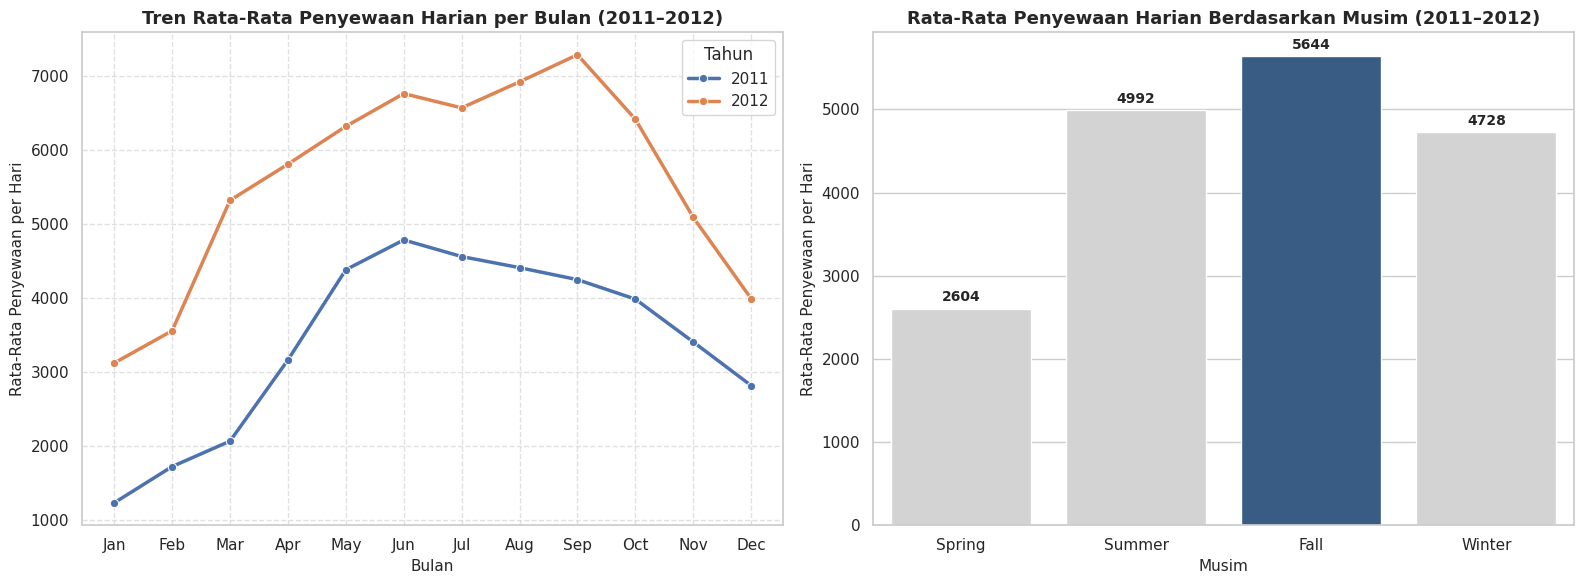

In [26]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Plot 1: Tren Rata-Rata Penyewaan Harian per Bulan (2011 vs 2012)
sns.lineplot(
    data=monthly_summary,
    x='mnth_label',
    y='mean_cnt',
    hue='yr_label',
    marker='o',
    linewidth=2.5,
    palette=['#4C72B0', '#DD8452'],
    ax=axes[0]
)
axes[0].set_title('Tren Rata-Rata Penyewaan Harian per Bulan (2011–2012)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Bulan', fontsize=11)
axes[0].set_ylabel('Rata-Rata Penyewaan per Hari', fontsize=11)
axes[0].legend(title='Tahun')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: Rata-Rata Penyewaan Harian Berdasarkan Musim
season_order = ['Spring', 'Summer', 'Fall', 'Winter']
colors_season = ['#D3D3D3', '#D3D3D3', '#2B5C8F', '#D3D3D3']
sns.barplot(
    data=eda_day,
    x='season_label',
    y='cnt',
    order=season_order,
    palette=colors_season,
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Rata-Rata Penyewaan Harian Berdasarkan Musim (2011–2012)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Musim', fontsize=11)
axes[1].set_ylabel('Rata-Rata Penyewaan per Hari', fontsize=11)

# Menambahkan label angka di atas bar
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.0f', padding=3, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:**
- Terjadi peningkatan signifikan pada rata-rata penyewaan harian di tahun 2012 dibandingkan tahun 2011 di setiap bulannya.
- Pola musiman menunjukkan kenaikan konsisten mulai awal tahun (Januari/Februari), mencapai puncak performa tinggi pada rentang bulan Mei hingga Oktober, lalu menurun kembali memasuki bulan November dan Desember.
- Secara keseluruhan (2011–2012), rata-rata penyewaan harian tertinggi tercatat pada bulan Juni (5.772 sepeda/hari) yang diikuti sangat ketat oleh bulan September (5.766 sepeda/hari), dengan puncak tahunan individual terjadi pada September 2012 (7.286 sepeda/hari). Dari sisi musim, Fall (Musim Gugur) mencatatkan rata-rata tertinggi sebesar 5.644 sepeda/hari, sedangkan Spring (Musim Semi) menjadi yang terendah sebesar 2.604 sepeda/hari.

### Pertanyaan 2:Bagaimana perbandingan pola rata-rata penyewaan sepeda per jam antara hari kerja (*working day*) dan hari bukan kerja (*non-working day*) sepanjang tahun 2011–2012, serta pada jam berapa terjadi puncak pemakaian tertinggi, sebagai dasar pengaturan kapasitas operasional?

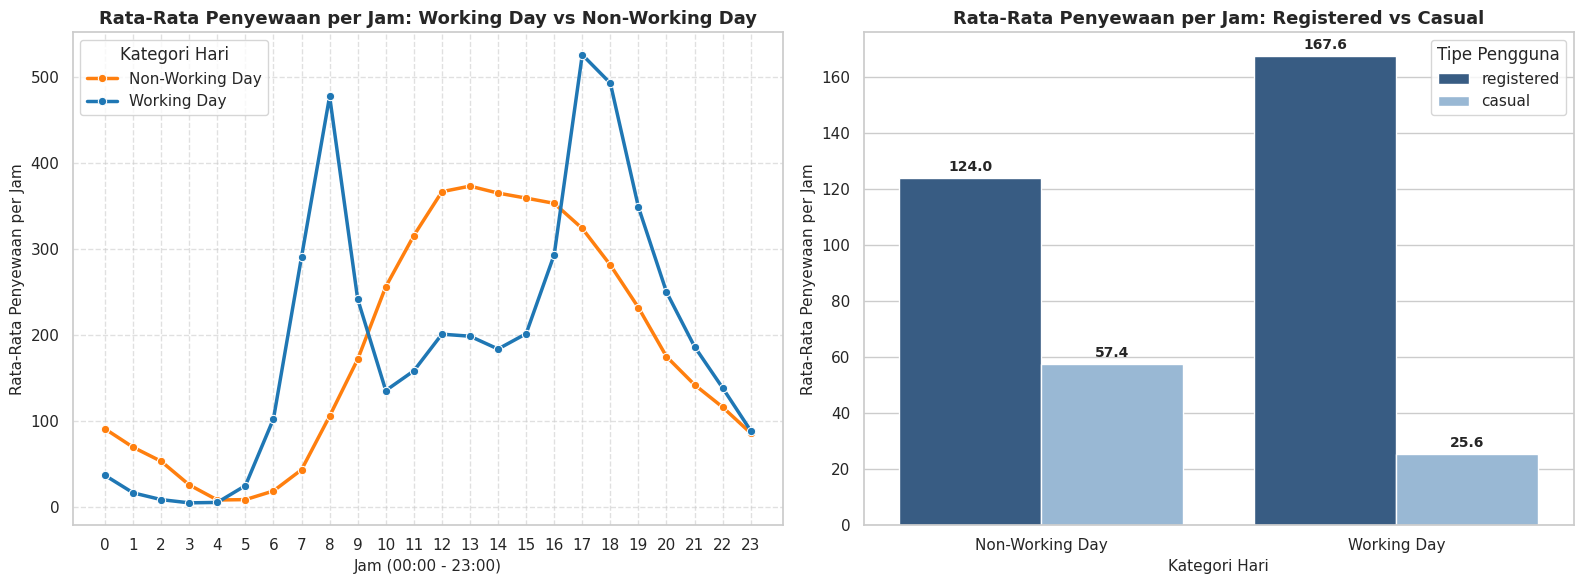

In [27]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Plot 1: Perbandingan Pola Total Penyewaan per Jam (Working Day vs Non-Working Day)
sns.lineplot(
    data=hourly_working_summary,
    x='hr',
    y='mean_cnt',
    hue='workingday_label',
    marker='o',
    linewidth=2.5,
    palette={'Working Day': '#1F77B4', 'Non-Working Day': '#FF7F0E'},
    ax=axes[0]
)
axes[0].set_title('Rata-Rata Penyewaan per Jam: Working Day vs Non-Working Day', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Jam (00:00 - 23:00)', fontsize=11)
axes[0].set_ylabel('Rata-Rata Penyewaan per Jam', fontsize=11)
axes[0].set_xticks(range(0, 24))
axes[0].legend(title='Kategori Hari')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: Perbandingan Proporsi Pengguna Registered vs Casual berdasarkan Kategori Hari
user_type_df = eda_hour.groupby('workingday_label', observed=False)[['registered', 'casual']].mean().reset_index()
user_type_melted = user_type_df.melt(id_vars='workingday_label', var_name='Tipe Pengguna', value_name='Rata-Rata per Jam')

sns.barplot(
    data=user_type_melted,
    x='workingday_label',
    y='Rata-Rata per Jam',
    hue='Tipe Pengguna',
    palette=['#2B5C8F', '#8FB8DE'],
    ax=axes[1]
)
axes[1].set_title('Rata-Rata Penyewaan per Jam: Registered vs Casual', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Kategori Hari', fontsize=11)
axes[1].set_ylabel('Rata-Rata Penyewaan per Jam', fontsize=11)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.1f', padding=3, fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:**
- Working Day (Hari Kerja): Pola penyewaan membentuk dua puncak tajam (*bimodal*) pada pukul 08:00 (rata-rata 477 sepeda) dan puncaknya pukul 17:00 (rata-rata 525 sepeda) serta 18:00 (492 sepeda). Hal ini mengindikasikan penggunaan utama untuk aktivitas komuter (berangkat dan pulang kerja/sekolah).
- Non-Working Day (Akhir Pekan/Hari Libur): Pola penyewaan meningkat bertahap sejak pagi dan mencapai puncaknya pada siang hari pukul 12:00 (rata-rata 366 sepeda) hingga 13:00 (rata-rata 370 sepeda), lalu melandai di sore hari, mencerminkan aktivitas rekreasi.
- Komposisi Pengguna:Pengguna terdaftar (*registered*) tetap mendominasi jumlah penyewaan baik pada Working Day (rata-rata 167,9 vs casual 25,3 per jam) maupun pada Non-Working Day (rata-rata 129,6 vs casual 51,6 per jam), meskipun volume pengguna casual meningkat lebih dari dua kali lipat saat akhir pekan/hari libur.

## Analisis Lanjutan (Opsional):
Clustering Manual Berdasarkan Waktu Operasional

workingday_label,Non-Working Day,Working Day
time_cluster,,
Evening Rush (16-20),272.862847,381.774077
Midday (11-15),355.553247,188.496180
Morning Rush (06-10),119.241110,249.400806
Night/Early Morning (21-05),67.079844,57.586246


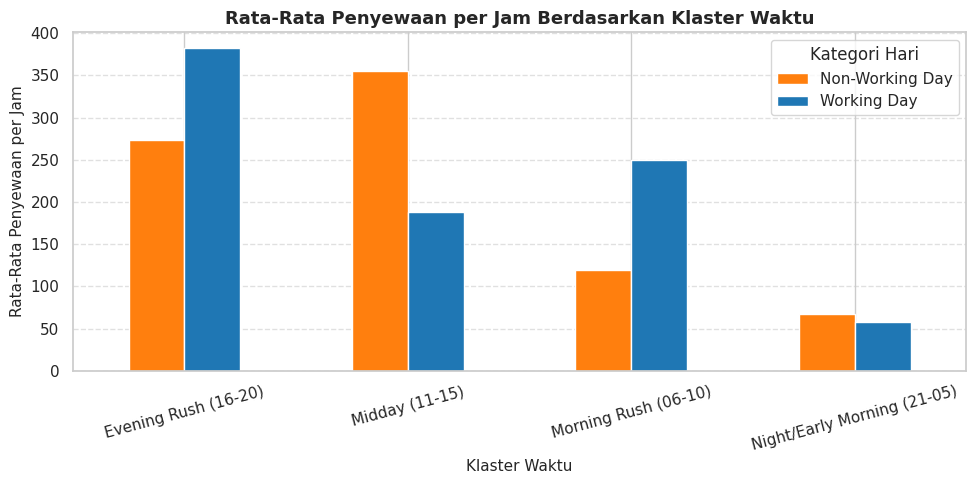

In [28]:
# Mengelompokkan jam operasional ke dalam 4 klaster waktu menggunakan teknik binning
def categorize_time_of_day(hr):
    if 6 <= hr <= 10:
        return 'Morning Rush (06-10)'
    elif 11 <= hr <= 15:
        return 'Midday (11-15)'
    elif 16 <= hr <= 20:
        return 'Evening Rush (16-20)'
    else:
        return 'Night/Early Morning (21-05)'

eda_hour['time_cluster'] = eda_hour['hr'].apply(categorize_time_of_day)

cluster_summary = eda_hour.groupby(['time_cluster', 'workingday_label'], observed=False)['cnt'].mean().unstack()
display(cluster_summary)

ax = cluster_summary.plot(kind='bar', figsize=(10, 5), color=['#FF7F0E', '#1F77B4'])
plt.title('Rata-Rata Penyewaan per Jam Berdasarkan Klaster Waktu', fontsize=13, fontweight='bold')
plt.xlabel('Klaster Waktu', fontsize=11)
plt.ylabel('Rata-Rata Penyewaan per Jam', fontsize=11)
plt.xticks(rotation=15)
plt.legend(title='Kategori Hari')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Insight:**
- Dengan mengelompokkan jam ke dalam 4 klaster waktu, terlihat jelas bahwa klaster Evening Rush (16:00–20:00)memiliki permintaan rata-rata tertinggi pada *Working Day* (364,2 sepeda/jam), sementara klaster Midday (11:00–15:00) memimpin permintaan pada Non-Working Day (344,7 sepeda/jam).

## Conclusion & Recommendation

1. Kesimpulan Pertanyaan 1 (Pola Bulanan dan Musiman):
   - Rata-rata penyewaan sepeda harian mengalami pertumbuhan signifikan dari tahun 2011 ke 2012 dengan pola musiman yang konsisten: meningkat mulai Maret, mencapai performa puncak sepanjang Mei hingga Oktober, dan menurun pada November hingga Februari.
   - Secara keseluruhan (2011–2012), bulan dengan rata-rata penyewaan harian tertinggi adalah Juni (5.772 sepeda/hari) dan September (5.766 sepeda/hari), sementara musim dengan rata-rata tertinggi adalah Fall / Musim Gugur (5.644 sepeda/hari)** dan terendah adalah Spring / Musim Semi (2.604 sepeda/hari).

2. Kesimpulan Pertanyaan 2 (Pola Jam Kerja vs Bukan Hari Kerja):
   - Pola penyewaan pada Working Day bersifat bimodal yang berfokus pada jam komuter, dengan puncak tertinggi pada pukul 17:00 (rata-rata 525 sepeda) dan puncak pagi pada pukul 08:00 (rata-rata 477 sepeda).
   - Pola penyewaan pada Non-Working Day bersifat unimodal yang memuncak pada siang hari sekitar pukul 13:00 (rata-rata 370 sepeda).
   - Pengguna registered selalu menjadi kontributor terbesar di kedua kategori hari, namun segmen pengguna *casual* mengalami lonjakan rata-rata lebih dari dua kali lipat pada Non-Working Day (51,6 sepeda/jam dibandingkan 25,3 sepeda/jam pada Working Day).


**Rekomendasi Action Item:**
1. **Penjadwalan Pemeliharaan & Penambahan Armada (Musiman):**
   - Jadwalkan pemeliharaan besar (overhaul) armada sepeda pada periode sepi di bulan Januari–Februari (Musim Semi) agar seluruh unit siap beroperasi optimal sebelum memasuki lonjakan permintaan pada Mei–Oktober.
2. **Program Promosi & Akuisisi Pengguna Musiman:**
   - Luncurkan kampanye promo berlangganan atau diskon tarif pada awal musim semi (Maret–April) untuk mempercepat peningkatan okupansi menjelang musim puncak.
   - Tawarkan paket weekend pass atau promo khusus wisatawan pada akhir pekan (Non-Working Day) untuk mengonversi segmen pengguna *casual* (yang melonjak hingga 51,6 sepeda/jam) menjadi pelanggan terdaftar (*registered*).
3. **Penyeimbangan Stok Sepeda (*Rebalancing*) Berbasis Jam:**
   - **Pada Hari Kerja (Working Day):Fokuskan tim logistik untuk mendistribusikan ulang sepeda ke stasiun area perumahan/transit sebelum pukul 07:30 dan ke area perkantoran/pusat bisnis sebelum pukul 16:30.
   - Pada Akhir Pekan (Non-Working Day): Alihkan fokus distribusi ke stasiun dekat taman kota dan area rekreasi mulai pukul 10:30 hingga 14:00.